In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
with open('../../output/qrf-hyperparam.pkl', 'rb+') as f:
    qrf_hyper = pickle.load(f)
with open('../../output/qrf-tree-count-losses.pkl', 'rb+') as f:
    qrf_tree_count = pickle.load(f)

In [3]:
df_hyper = pd.DataFrame(qrf_hyper).melt()
df_hyper.columns = ['max_samples_leaf', 'max_features', 'max_samples', 'max_depth', 'value']
df_hyper['loss_low'] = df_hyper['value'].apply(lambda x: x[0])
df_hyper['loss_high'] = df_hyper['value'].apply(lambda x: x[1])
df_hyper.drop(columns=['value'], inplace=True)

In [4]:
df_hyper.iloc[df_hyper['loss_low'].argmin(), :]

max_samples_leaf           5
max_features            0.75
max_samples             0.75
max_depth                 32
loss_low            0.005147
loss_high           0.005311
Name: 22, dtype: object

In [5]:
df_hyper.iloc[df_hyper['loss_high'].argmin(), :]

max_samples_leaf           5
max_features            0.75
max_samples             0.75
max_depth                 32
loss_low            0.005147
loss_high           0.005311
Name: 22, dtype: object

In [6]:
df_trees_loss = pd.DataFrame(qrf_tree_count).melt()\
    .rename(columns={'variable': 'N trees', 'value': 'Loss'})

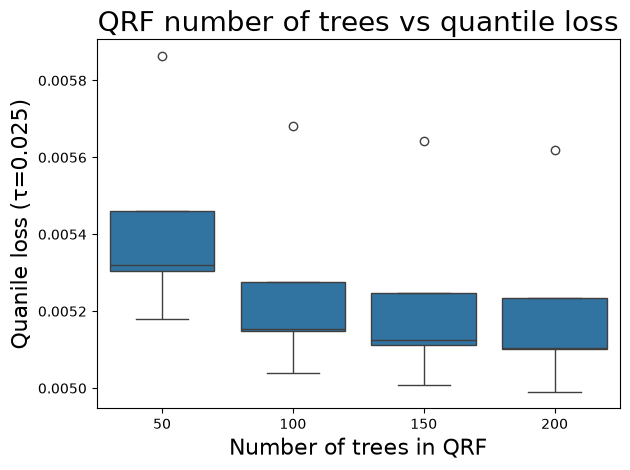

In [7]:
import seaborn as sns
sns.boxplot(df_trees_loss, x='N trees', y='Loss')
plt.ylabel('Quanile loss (\u03C4=0.025)', size=16)
plt.xlabel('Number of trees in QRF', size=16)
plt.title('QRF number of trees vs quantile loss', size=20)
plt.tight_layout()
plt.savefig('../images/tree-count-yipeng3.png', dpi=750)
plt.show()

In [8]:
qrf_tree_count

{200: [0.005102261084798383,
  0.004990710108780049,
  0.00523326214697732,
  0.005618890910485118,
  0.005105120031731956],
 150: [0.005111353930554616,
  0.005007062496448176,
  0.005248205436846556,
  0.005642076236308141,
  0.005125998052933028],
 100: [0.005148685180231446,
  0.005039982359332118,
  0.00527544762633302,
  0.005682342155382048,
  0.005154889862506532],
 50: [0.0053053179128307315,
  0.005179166593347538,
  0.00546054412021236,
  0.00586305106507425,
  0.005319448649245172]}

In [9]:
import numpy as np
import quantile_forest as qrf

In [10]:
X_train = np.load('../../output/data_yipeng3/qrf/X_train.npy')
y_train = np.load('../../output/data_yipeng3/qrf/y_train.npy')

SLIDINGW_STEPS = 5
N_OUT_FEATS = y_train.shape[-1]
N_INP_FEATS = X_train.shape[-1]

y_train = y_train.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_train = X_train.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [11]:
best_params = {
    'n_estimators': 100,
    'max_depth': 32,
    'max_samples': 0.75,
    'max_features': 0.75,
    'max_samples_leaf': 5,
}

In [ ]:
qrf_best = qrf.RandomForestQuantileRegressor(**best_params, n_jobs=-1, random_state=42)\
    .fit(X_train, y_train)

In [ ]:

X_val = np.load('../../output/data_yipeng3/qrf/X_val.npy')
y_val = np.load('../../output/data_yipeng3/qrf/y_val.npy')

y_val = y_val.reshape((-1, SLIDINGW_STEPS*N_OUT_FEATS))
X_val = X_val.reshape((-1, SLIDINGW_STEPS*N_INP_FEATS))

In [ ]:

y_val_pred = qrf_best.predict(X_val, quantiles=[0.025, 0.975])
y_val_low = y_val_pred[:, :, 0]
y_val_high = y_val_pred[:, :, 1]

val_mmsis = np.load('../../output/data_yipeng3/qrf/val-mmsis.npy', allow_pickle=True)
val_days = np.load('../../output/data_yipeng3/qrf/val-days.npy', allow_pickle=True)

In [ ]:
in_pi_mask = (y_val > y_val_low) & (y_val < y_val_high)
in_pi_mask = in_pi_mask.reshape((-1, 5, 3))

group_results = {}
for ix, (mmsi, day) in enumerate(zip(val_mmsis, val_days)):
    
    if (mmsi, day) not in group_results:
        group_results[(mmsi, day)] = [ in_pi_mask[ix, :, :] ]
    else:
        group_results[(mmsi, day)].append( in_pi_mask[ix, :, :] )

df = []

for (mmsi, day), pi_masks in group_results.items():
    means = np.array(pi_masks).mean(axis=1).mean(axis=0)
    df.append({
        'mmsi': mmsi,
        'day': day,
        'delta_cog': means[0],
        'delta_dif': means[1],
        'dif': means[2]
    })

df = pd.DataFrame(df)

thresh_delta_cog = np.quantile(df['delta_cog'], 0.05)
thresh_delta_dif = np.quantile(df['delta_dif'], 0.05)
thresh_dif = np.quantile(df['dif'], 0.05)

print( 'delta_cog limit:', np.quantile(df['delta_cog'], 0.05) )
print( 'delta_dif liimt:', np.quantile(df['delta_dif'], 0.05) )
print( 'dif liimt:', np.quantile(df['dif'], 0.05) )

In [ ]:
yipeng3_y = np.load('../../output/data_yipeng3/qrf/yipeng3_y.npy', allow_pickle=True)\
    .reshape((-1, 5*3))
yipeng3_x = np.load('../../output/data_yipeng3/qrf/yipeng3_x.npy', allow_pickle=True)\
    .reshape((-1, 5*20))

In [ ]:
yipeng3_model_out = qrf_best.predict(yipeng3_x, quantiles=[0.025, 0.975])
yipeng3_low, yipeng3_high = yipeng3_model_out[:, :, 0], yipeng3_model_out[:, :, 1]

for feat in range(3):
    print(
        np.mean( (
            (yipeng3_low[75:, feat] < yi_y[75:, feat]) &
            (yipeng3_high[75:, feat] > yipeng3_y[75:, feat])
        ) )
    )

    plt.plot(yipeng3_low[75:, feat])
    plt.plot(yipeng3_high[75:, feat])
    plt.plot(yipeng3_y[75:, feat])
    plt.show()